# 25 — Binary Runge Kutta Optimizer (BRUN) for feature selection

Continuous algorithm: *Ahmadianfar I. et al. (2021). RUN beyond the metaphor. Expert Syst. Appl.*  
Binarised with the **Unified Binarization Framework (UBF)**: deterministic sign mapping, density-diverse initial population, fitness memoisation and elite bit-flip local search. RS = random-search control under the same framework. Protocol: see `00_data_and_protocol`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fsbench import experiment as ex, plots
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
METHOD = "RUN"
recs = ex.run_method(METHOD)
base = {m: ex.run_method(m) for m in ("ANOVA", "Chi2", "AllFeatures", "RS")}
df = ex.flatten(recs)
print(len(recs), "runs")

80 runs


## Performance on the test split (mean ± std over 10 runs)

In [3]:
plots.summary_table(df, by=("dataset", "classifier"))

,dataset,classifier,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,search_time_s
0,dermatology,ANN,0.9727 ± 0.0105,0.9727 ± 0.011,0.9686 ± 0.0106,0.9698 ± 0.0106,0.9979 ± 0.0008,17.7 ± 1.8288,9.7807 ± 1.3452
1,dermatology,DT,0.9545 ± 0.0206,0.953 ± 0.0212,0.9434 ± 0.0259,0.9472 ± 0.0235,0.9671 ± 0.0149,17.7 ± 1.8288,9.7807 ± 1.3452
2,dermatology,KNN,0.9536 ± 0.0225,0.9518 ± 0.0221,0.9427 ± 0.0291,0.9455 ± 0.0261,0.9945 ± 0.0054,17.7 ± 1.8288,9.7807 ± 1.3452
3,dermatology,RF,0.9682 ± 0.0098,0.9665 ± 0.0122,0.9615 ± 0.014,0.9632 ± 0.0127,0.9978 ± 0.0006,17.7 ± 1.8288,9.7807 ± 1.3452
4,dermatology,SVM,0.9627 ± 0.0145,0.9643 ± 0.0158,0.9582 ± 0.0143,0.9595 ± 0.0146,0.9974 ± 0.0012,17.7 ± 1.8288,9.7807 ± 1.3452
5,dermatology,XGB,0.9645 ± 0.009,0.9635 ± 0.0118,0.9587 ± 0.0096,0.9599 ± 0.01,0.9943 ± 0.0027,17.7 ± 1.8288,9.7807 ± 1.3452
6,ionosphere,ANN,0.8915 ± 0.0149,0.8894 ± 0.0155,0.8725 ± 0.0191,0.8795 ± 0.0173,0.9239 ± 0.0268,6.8 ± 2.2509,7.6334 ± 1.0393
7,ionosphere,DT,0.8802 ± 0.0218,0.8715 ± 0.0245,0.8683 ± 0.0248,0.8693 ± 0.0237,0.8678 ± 0.0244,6.8 ± 2.2509,7.6334 ± 1.0393
8,ionosphere,KNN,0.8849 ± 0.0217,0.8988 ± 0.0184,0.8517 ± 0.0294,0.8675 ± 0.0268,0.9122 ± 0.0254,6.8 ± 2.2509,7.6334 ± 1.0393
9,ionosphere,RF,0.9075 ± 0.0198,0.9077 ± 0.0187,0.8896 ± 0.0258,0.8971 ± 0.0228,0.9564 ± 0.0179,6.8 ± 2.2509,7.6334 ± 1.0393


## Comparison with the classical filters (F1-macro, averaged over the six classifiers)

In [4]:
allb = pd.concat([df] + [ex.flatten(r) for r in base.values()])
pivot = allb.groupby(["dataset", "method"]).f1_macro.mean().unstack().round(4)
pivot

method,ANOVA,AllFeatures,Chi2,RS,RUN
dataset,,,,,
dermatology,0.9676,0.9568,0.9568,0.9552,0.9575
ionosphere,0.8734,0.8907,0.8734,0.8765,0.8811
musk1,0.8449,0.8634,0.8603,0.8553,0.8626
sonar,0.8293,0.8317,0.8188,0.7940,0.7942
spectf,0.5448,0.5448,0.5448,0.5471,0.5479
vehicle,0.6656,0.7311,0.6558,0.7273,0.7146
wdbc,0.9294,0.9442,0.9462,0.9291,0.9370
wine,0.9628,0.9524,0.9542,0.9530,0.9639


In [5]:
allb.groupby(["dataset", "method"])[["n_selected", "search_time_s"]].mean().unstack().round(2)

n_selected                                search_time_s                                
method           ANOVA AllFeatures   Chi2    RS   RUN         ANOVA AllFeatures  Chi2     RS    RUN
dataset                                                                                            
dermatology       24.0        34.0   34.0  18.1  17.7          0.36         0.0  0.23  13.37   9.78
ionosphere         3.0        33.0    3.0   6.4   6.8          0.33         0.0  0.32  15.02   7.63
musk1             66.0       166.0  133.0  55.9  59.2          0.38         0.0  0.28  21.06  16.29
sonar             24.0        60.0   30.0  21.5  23.2          0.30         0.0  0.28  11.13   8.62
spectf            44.0        44.0   44.0  16.9  20.5          0.31         0.0  0.20  12.17   8.89
vehicle            9.0        18.0    7.0  10.1   9.0          0.46         0.0  0.49  28.40   9.81
wdbc              18.0        30.0   21.0   9.9  10.8          0.37         0.0  0.35  20.84  10.45
wine               9.0        13.0    8.0   5.8   5.6          0.18         0.0  0.19   7.11   3.23

## Convergence: best-so-far fitness per iteration
A flat tail means the search converged within the budget; a still-decreasing tail means more iterations could help.

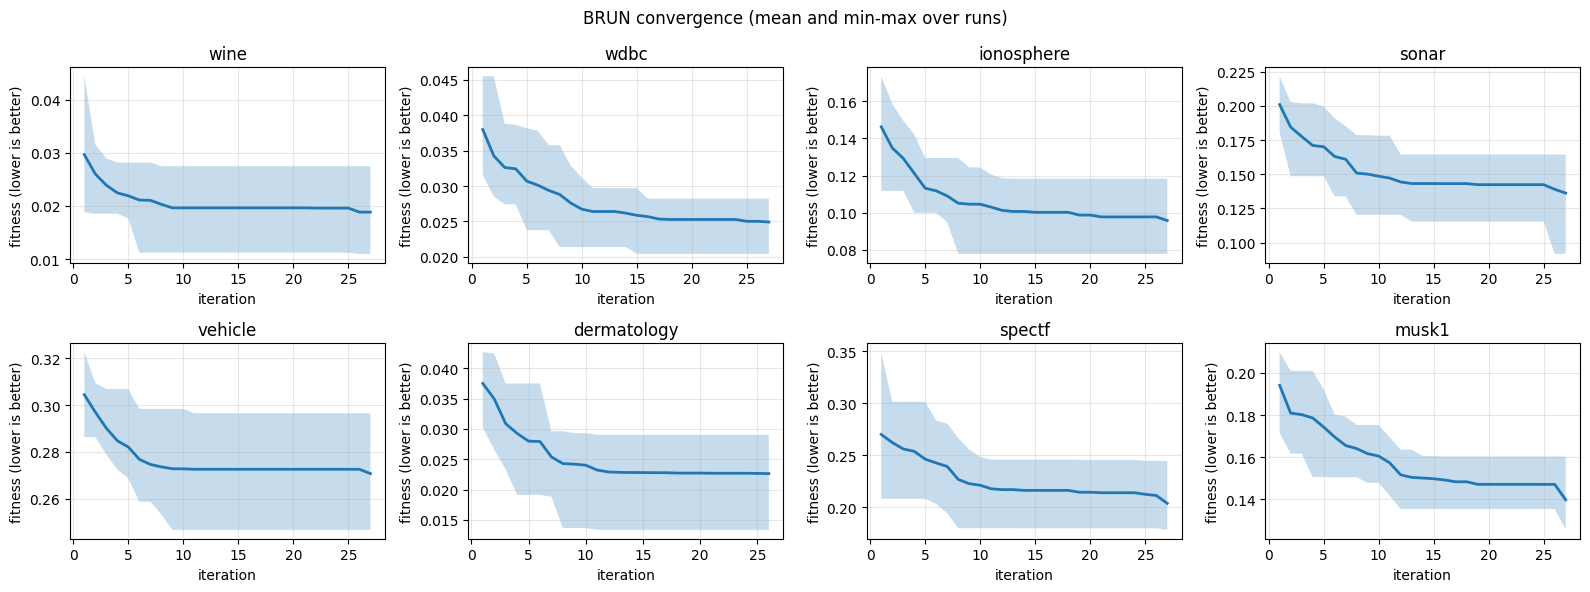

In [6]:
plots.convergence(recs, title="BRUN convergence (mean and min-max over runs)", name="convergence_RUN");

## Confusion matrices and ROC curves (run 0, KNN)

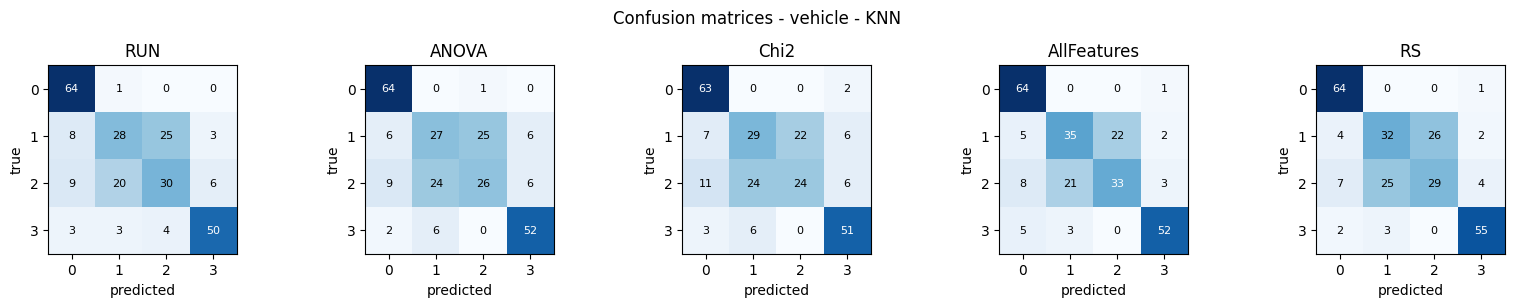

In [7]:
ds = "vehicle"
plots.confusion_matrices({METHOD: recs, **base}, ds, name=f"cm_{METHOD}_{ds}");

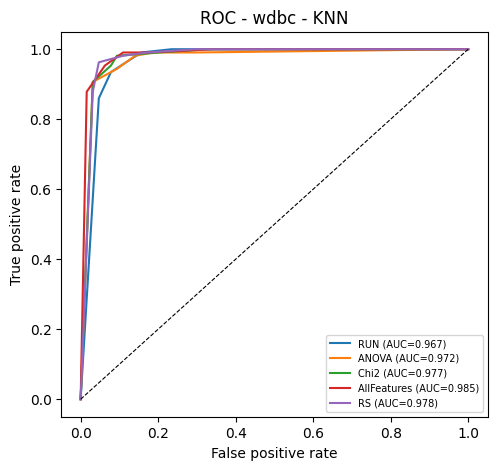

In [8]:
plots.roc_curves({METHOD: recs, **base}, "wdbc", name=f"roc_{METHOD}_wdbc");

## Computation
`n_classifier_fits` counts real classifier trainings; `cache_hits` are FEs served by the memo.

In [9]:
pd.DataFrame([{k: r[k] for k in ("dataset", "run", "n_selected", "time_s", "n_classifier_fits", "cache_hits")} for r in recs]).groupby("dataset").mean().round(2)

,run,n_selected,time_s,n_classifier_fits,cache_hits
dataset,,,,,
dermatology,4.5,17.7,9.78,452.3,547.8
ionosphere,4.5,6.8,7.63,407.9,592.7
musk1,4.5,59.2,16.29,645.3,354.9
sonar,4.5,23.2,8.62,517.6,482.4
spectf,4.5,20.5,8.89,488.8,511.7
vehicle,4.5,9.0,9.81,305.0,695.7
wdbc,4.5,10.8,10.45,434.0,566.6
wine,4.5,5.6,3.23,245.3,755.0
